In [ ]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# from helperModules impaort helperModules
from importlib import reload
# import RWTHColors
import re
import textwrap

In [25]:
# h5folder = Path(r'I:\002Simulation_EBSD\NbNiBandProfiles\NbNiLPR_58Nb42Ni_IL')
# h5folder = Path(r'J:\Users\Berners_Lukas\clara\NbCoUBC\48Nb52Co_verticalCut\Area2\Map1\NbCo3aILGrid_LPR_Low_2026_01\cleaned')
h5folder = Path(r'J:\Users\Berners_Lukas\clara\NbCoUBC\56Nb44Co_verticalCut\Area3\Map1\NbCo3aILGrid_LPR_High_2026_01\cleaned')
#  h5folder = Path(r"J:\Users\Berners_Lukas\clara\SiWafer\EBSD Calib\GradientTesting")
# h5folder = Path(r'E:\sciebo\IMM\EBSD\Calibration\CalibrationLandscape\MinimizationQuality\OptiLandscape')



h5fileList = list(h5folder.glob('*58Nb*.hdf5_repro'))
h5fileList

[WindowsPath('E:/sciebo/IMM/BandProfiles/PlottingFromkH5Refinement/2026-02-13T19-23-20.551388_ANALYZED_DATA_berners_NbNi_58Nb-Ni_V2_september_Area 7_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR58Nb_42Ni_2026_01_cleaned.hdf5_repro')]

<>:124: SyntaxWarning: invalid escape sequence '\B'
<>:125: SyntaxWarning: invalid escape sequence '\B'
<>:126: SyntaxWarning: invalid escape sequence '\B'
<>:124: SyntaxWarning: invalid escape sequence '\B'
<>:125: SyntaxWarning: invalid escape sequence '\B'
<>:126: SyntaxWarning: invalid escape sequence '\B'
C:\Users\berners\AppData\Local\Temp\ipykernel_1316\1653787407.py:124: SyntaxWarning: invalid escape sequence '\B'
  plt.savefig(f"{exportFolder}\BandProfiles.png",bbox_inches='tight',dpi=300)
C:\Users\berners\AppData\Local\Temp\ipykernel_1316\1653787407.py:125: SyntaxWarning: invalid escape sequence '\B'
  plt.savefig(f"{exportFolder}\BandProfiles.svg",bbox_inches='tight')
C:\Users\berners\AppData\Local\Temp\ipykernel_1316\1653787407.py:126: SyntaxWarning: invalid escape sequence '\B'
  plt.savefig(f"{exportFolder}\BandProfiles.pdf",bbox_inches='tight')


E:\sciebo\IMM\BandProfiles\PlottingFromkH5Refinement\2026-02-13T19-23-20.551388_ANALYZED_DATA_berners_NbNi_58Nb-Ni_V2_september_Area 7_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR58Nb_42Ni_2026_01_cleaned.hdf5_repro
<HDF5 file "2026-02-13T19-23-20.551388_ANALYZED_DATA_berners_NbNi_58Nb-Ni_V2_september_Area 7_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR58Nb_42Ni_2026_01_cleaned.hdf5_repro" (mode r)>
NbNi_c27.025_a4.96_6c2-0.250_3aNb-1.000__19.4kV_dmin0.020
0
NbNi_c27.025_a4.96_6c2-0.275_3aNb-1.000__19.4kV_dmin0.020
1
NbNi_c27.025_a4.96_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020
2
NbNi_c27.025_a4.96_6c2-0.350_3aNb-1.000__19.4kV_dmin0.020
3
NbNi_c27.025_a4.96_6c2-0.375_3aNb-1.000__19.4kV_dmin0.020
4
NbNi_c27.025_a4.96_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020
5
NbNi_c27.025_a4.96_6c2-0.425_3aNb-1.000__19.4kV_dmin0.020
6
NbNi_c27.025_a4.96_6c2-0.450_3aNb-1.000__19.4kV_dmin0.020
7


C:\Users\lukas\AppData\Local\Temp\ipykernel_8648\3575378379.py:115: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.savefig(f"{exportFolder}/BandProfiles_{h5fileIn.stem}.png",bbox_inches='tight',dpi=300)
C:\Users\lukas\AppData\Local\Temp\ipykernel_8648\3575378379.py:116: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.savefig(f"{exportFolder}/BandProfiles_{h5fileIn.stem}.svg",bbox_inches='tight')
C:\Users\lukas\AppData\Local\Temp\ipykernel_8648\3575378379.py:117: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.savefig(f"{exportFolder}/BandProfiles_{h5fileIn.stem}.pdf",bbox_inches='tight')
C:\Users\lukas\AppData\Local\Temp\ipykernel_8648\3575378379.py:117: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small en

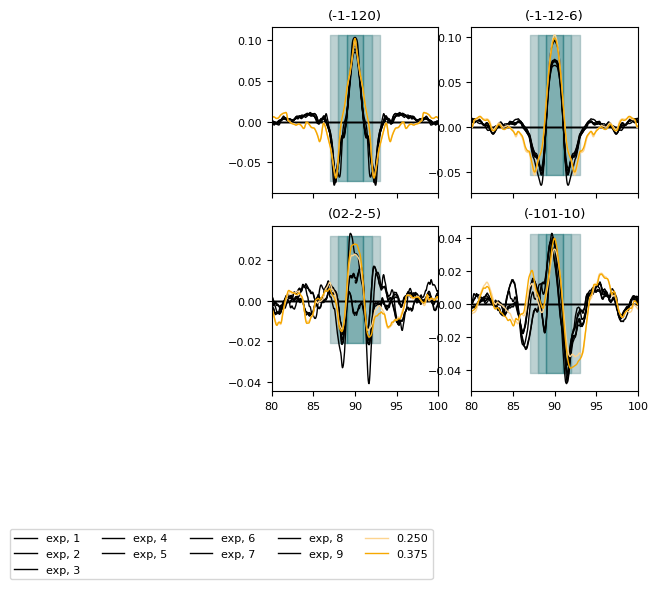

In [36]:

# h5fileList = ['GradientsAluminum_PatSize514_n3_Noise_18.00','GradientsAluminum_PatSize514_n3_Noise_23.00','GradientsAluminum_PatSize514_n3_Noise_30.00']
# h5fileList = ['GTestAluminum_PatSize514_n3_Noise_18.00']
# h5fileList = h5folder.glob('StereogrpahicBandProfiles2.hdf5')
import matplotlib.ticker as ticker
from RWTHColors import ColorManager
colMan = ColorManager()
colorList = [colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(75),colMan.RWTHPetrol.p(50),colMan.RWTHPetrol.p(25),colMan.RWTHPetrol.p(10), colMan.RWTHGruen.p(100), colMan.RWTHGruen.p(75), colMan.RWTHGruen.p(50),colMan.RWTHBlau.p(100),colMan.RWTHBlau.p(75),colMan.RWTHBlau.p(50)]
plotcolorList = [colMan.RWTHOrange.p(50), colMan.RWTHGruen.p(75), colMan.RWTHGruen.p(50),colMan.RWTHOrange.p(100),colMan.RWTHOrange.p(100),colMan.RWTHBlau.p(50)]

plt.style.use('pltstyle.mplstyle')
cm = 1/2.54


h5fileList = list(h5folder.glob('*58Nb*.hdf5_repro'))
# noise = [18,23,30]
# counts = 0
df_all =[]
# reload(helperModules)
fig, axs = plt.subplots(2,2, figsize=(12*cm, 12*cm), layout='tight',sharex=True)
vkey = '19.30kV'
ax = axs.flatten()
maxPlots = 4
for h5fileIn in h5fileList:
    print(h5fileIn)
    minBandVals = {}
    maxBandVals =  {}
    # h5fileIn = 'GradientsAluminum_PatSize514_n3_Noise_18.00'
    h5file = f'{h5fileIn.stem}.hdf5_repro'
    exportFolder = Path(f"\\\\?\\{h5folder.joinpath(h5fileIn.stem)}")
    exportFolder.mkdir(parents=True,exist_ok=True )
    # noiseSetting = 
    f = h5py.File(f"\\\\?\\{h5folder.joinpath(h5file)}", 'r')
    print(f)
    phaseNamesClean =[]
    keyNum = 0
    for key in f["RTM"].keys():
        print(key)
        print(keyNum)
        print(keyNum)
        if keyNum >=0:
            phaseNamesClean.append(key)# = [ string(phaseNames{phaseNum}) ];

            BandProfiles = f["RTM"][key]["RTMPCA"]["1"]['Bandprofiles']
            # uniqueBands = f["RTM"][key]["RTMPCA"]["1"]['BandNameGroups']
            uniqueBands = f["RTM"][key]["RTMPCA"]["1"]["Bandprofiles"]['bandNameGroups'][:]
            numUniqueBands = np.unique(uniqueBands)
            numUniqueBands
            i = 0
            # try

            for bNum in numUniqueBands:
                print(BandProfiles) 
                bKey = str(bNum)
                indices = np.where(bNum==uniqueBands)
                bandIndex = indices[1][[0]]
                numBands = BandProfiles['bandValuesExp'].shape[0]
                # print(bandIndex[0])
                thetaoffset = BandProfiles["1"]["thetaValues"][0]*360/(2*np.pi)

                pattern = r'6c2-(\d*\.\d+|\d+)'

                # Search for the pattern
                plotName = re.search(pattern, key)
                plotName = plotName.group(1)
                # plotName = key
                # maxBandVal = np.max([maxBandVal,np.max(BandProfiles['bandValuesSim'][bandIndex[0],:])])
                # minBandVal = np.min([minBandVal,np.min(BandProfiles['bandValuesSim'][bandIndex[0],:])])
                bandValsSim = BandProfiles['bandValuesSim'][bandIndex[0],:]
                bandValsSim = bandValsSim - np.nanmean(bandValsSim)
                pNum = 0
                for Pnumkey in BandProfiles.keys():

                    if not isinstance( BandProfiles[Pnumkey] , h5py.Dataset):
                        # print(key)
                        # print(type(BandProfiles[key]))
                        # print(BandProfiles[key])
                        bandValsExp= BandProfiles[Pnumkey]['bandValuesExp'][bandIndex[0],:]
                        bandValsExp = bandValsExp - np.nanmean(bandValsExp)
                        if keyNum==0:

                            minBandVals[bKey] = np.nanmin(bandValsExp)
                            maxBandVals[bKey] = np.nanmax(bandValsExp)
                
                            ax[i].plot(BandProfiles['openingAngles'],bandValsExp,label="\n".join(textwrap.wrap(f"exp, {Pnumkey}",width = 50)),color='black')


                    pNum+=1
                if keyNum == 4 or keyNum ==0:
                    ax[i].plot(BandProfiles['openingAngles'],bandValsSim,label="\n".join(textwrap.wrap(plotName,width = 50)),color=plotcolorList[keyNum])
                if keyNum ==4:
                    ax[i].set_title(BandProfiles['bandNames'][0,bandIndex[0]].decode())
                minBandVals[bKey] = np.nanmin([minBandVals[bKey],np.nanmin(bandValsSim)])
                maxBandVals[bKey] = np.nanmax([maxBandVals[bKey],np.nanmax(bandValsSim)])

                # if i == 0:#% numBands-1:
                #     ax[i].legend(bbox_to_anchor=(1,0),ncols=3)

                if keyNum >= len(f["RTM"].keys())-1:
                    ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-thetaoffset,90+thetaoffset,alpha = 0.5,color=colorList[0])
                    ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-thetaoffset,90-2*thetaoffset,alpha = 0.5,color=colorList[1])
                    ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90+thetaoffset,90+2*thetaoffset,alpha = 0.5,color=colorList[1])
                    ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-2*thetaoffset,90-3*thetaoffset,alpha = 0.5,color=colorList[2])
                    ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90+2*thetaoffset,90+3*thetaoffset,alpha = 0.5,color=colorList[2])
                    # ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-3*thetaoffset,90-4*thetaoffset,alpha = 0.5,color=colorList[3])
                    # ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90+3*thetaoffset,90+4*thetaoffset,alpha = 0.5,color=colorList[3])
                    # ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90-4*thetaoffset,90-5*thetaoffset,alpha = 0.5,color=colorList[4])
                    # ax[i].fill_betweenx([minBandVals[bKey],  maxBandVals[bKey] ],90+4*thetaoffset,90+5*thetaoffset,alpha = 0.5,color=colorList[4])                    
                    # ax[i].fill_betweenx([minBandVal,maxBandVal],90-2*thetaoffset,90+2*thetaoffset,alpha = 0.5,color=colorList[1])
                ax[i].set_xlim([80,100])
                i+=1
                # del maxBandVal 
                # del minBandVal 
                if i >= maxPlots:
                    break
                

        keyNum = keyNum+1
    # OptiLandscape.keys()
    # optiLandscapeToImage(OptiLandscape,'pcy_pcx',1)
    # OptiLandscape.keys()
    ax[0].legend(bbox_to_anchor=(1,  -2),ncols=5)
    # df = pd.concat(df_all),
    plt.savefig(f"{exportFolder}/BandProfiles_{h5fileIn.stem}.png",bbox_inches='tight',dpi=300)
    plt.savefig(f"{exportFolder}/BandProfiles_{h5fileIn.stem}.svg",bbox_inches='tight')
    plt.savefig(f"{exportFolder}/BandProfiles_{h5fileIn.stem}.pdf",bbox_inches='tight')

    # oriNum = 1
#     metricNames = list(BandProfiles.keys())
#     # gradientName = 
#     results = BandProfiles[metricNames[0]]
#     gradientName = list(results.keys())aaasdf
#     resultsInner = results[gradieaaName[0]]
#     resultsinnerKeys = list(resultsInner[f'Ori{oriNum}'].keys())
#     DataSets = list(resultsInner[f'Ori{oriNum}'][resultsinnerKeys[1]].keys())
#     # DataSets = ['roty_pcx','roty_pcx_Coarse']
#     # DataSets = ['pcy_pcx','pcy_pcx_Coarse']
#     # DataSets =['rotx_pcy_Coarse','rotx_pcy']
#     DataSets = ['roty_pcx','roty_pcx_Coarse','pcy_pcx','pcy_pcx_Coarse']
#     # fig,ax = plt.subplots(3,3)
#     # fig.tight_layout()
#     # ax= ax.flatten()
#     reload(helperModules)
#     numOri = 3
#     doPlot = 0
#     df = helperModules.caluclateDistribution(OptiLandscape,DataSets,numOri,doPlot)
#     df['noiseSetting']=noiseSetting
#     df['phase'] = phaseNamesClean[0]
#     counts = counts+1
#     df_all.append(df)



In [32]:
Pnumkey

'thetaValues'

In [28]:
bandValsExp= BandProfiles['bandValuesExp'][bandIndex[0],:]
bandValsExp = bandValsExp - np.mean(bandValsExp)
bandValsExp

array([-9.85741615e-04, -8.60929489e-04, -4.88311052e-04,  6.10053539e-05,
        6.29276037e-04,  7.27146864e-04,  2.00450420e-04, -5.98251820e-04,
       -1.06912851e-03, -7.71194696e-04, -6.04987144e-05,  4.82082367e-04,
        5.17696142e-04,  1.81645155e-04, -2.68578529e-04, -5.60224056e-04,
       -2.30789185e-04,  8.35299492e-04,  2.04390287e-03,  2.82725692e-03,
        3.01012397e-03,  2.70906091e-03,  2.13205814e-03,  1.58843398e-03,
        1.24502182e-03,  1.37329102e-03,  1.95774436e-03,  2.55370140e-03,
        2.60233879e-03,  2.18546391e-03,  1.56459212e-03,  1.11868978e-03,
        8.59975815e-04,  7.10487366e-04,  8.69929790e-04,  1.40997767e-03,
        1.98706985e-03,  2.22358108e-03,  1.93372369e-03,  1.66225433e-03,
        1.59770250e-03,  1.75404549e-03,  1.92430615e-03,  1.99291110e-03,
        2.16531754e-03,  2.32738256e-03,  2.33525038e-03,  2.13661790e-03,
        2.08932161e-03,  2.18477845e-03,  2.04876065e-03,  1.67274475e-03,
        1.17933750e-03,  

In [29]:
np.mean(bandValsExp)

np.float32(-1.4281312e-08)

In [30]:
maxBandVals[bNum]

KeyError: np.uint16(4)

In [ ]:
np.size(BandProfiles['openingAngles']),np.size(BandProfiles['bandValuesExp'][bandIndex[0],:])
# plt.plot(np.transpose(BandProfiles['openingAngles']),BandProfiles['bandValuesExp'][i,:],label="\n".join(textwrap.wrap(key,width = 50)))

(601, 601)

E:\sciebo\IMM\BandProfiles\PlottingFromkH5Refinement\2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro
<HDF5 file "2026-02-13T18-17-51.340449_ANALYZED_DATA_berners_NbNi_Nb-49Ni_V2_september_Area 10_EBSD+EDS Map 1_SinglePatRefinement_eangscommercial_pcFitted1_PCAMode_Tiles__NbNi3aILGrid_LPR51Nb_49Ni_2026_01_cleaned.hdf5_repro" (mode r)>
NbNi_c26.81_a4.92_6c2-0.250_3aNb-1.000__19.4kV_dmin0.020
0
NbNi_c26.81_a4.92_6c2-0.275_3aNb-1.000__19.4kV_dmin0.020
1
NbNi_c26.81_a4.92_6c2-0.300_3aNb-1.000__19.4kV_dmin0.020
2
NbNi_c26.81_a4.92_6c2-0.325_3aNb-1.000__19.4kV_dmin0.020
3
NbNi_c26.81_a4.92_6c2-0.350_3aNb-1.000__19.4kV_dmin0.020
4
NbNi_c26.81_a4.92_6c2-0.375_3aNb-1.000__19.4kV_dmin0.020
5
NbNi_c26.81_a4.92_6c2-0.400_3aNb-1.000__19.4kV_dmin0.020
6
NbNi_c26.81_a4.92_6c2-0.425_3aNb-1.000__19.4kV_dmin0.020
7
NbNi_c26.81_a4.92_6c2-0.450_

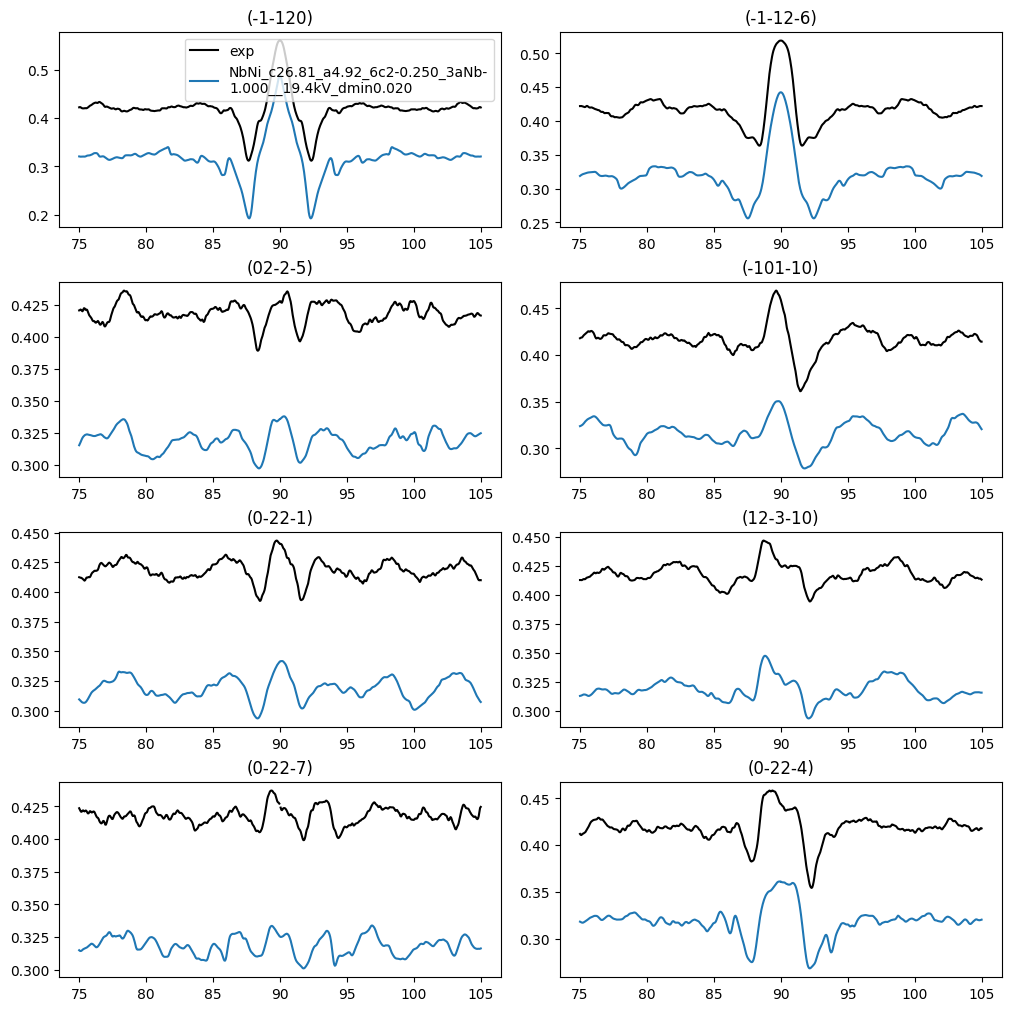

In [ ]:

# h5fileList = ['GradientsAluminum_PatSize514_n3_Noise_18.00','GradientsAluminum_PatSize514_n3_Noise_23.00','GradientsAluminum_PatSize514_n3_Noise_30.00']
# h5fileList = ['GTestAluminum_PatSize514_n3_Noise_18.00']
# h5fileList = h5folder.glob('StereogrpahicBandProfiles2.hdf5')
h5fileList = list(h5folder.glob('*51Nb*.hdf5_repro'))
# noise = [18,23,30]
# counts = 0
df_all =[]
reload(helperModules)
fig, axs = plt.subplots(4,2, figsize=(10, 10), layout='constrained')
vkey = '19.30kV'
ax = axs.flatten()
for h5fileIn in h5fileList:
    print(h5fileIn)

    # h5fileIn = 'GradientsAluminum_PatSize514_n3_Noise_18.00'
    h5file = f'{h5fileIn.stem}.hdf5_repro'
    exportFolder = h5folder.joinpath(h5fileIn.stem)
    exportFolder.mkdir(parents=True,exist_ok=True )
    # noiseSetting = 
    f = h5py.File(h5folder.joinpath(h5file), 'r')
    print(f)
    phaseNamesClean =[]
    keyNum = 0
    for key in f["RTM"].keys():
        print(key)
        print(keyNum)
        # if keyNum >=0:
        phaseNamesClean.append(key)# = [ string(phaseNames{phaseNum}) ];

        BandProfiles = f["RTM"][key]["RTMPCA"]["1"]['Bandprofiles']
        # uniqueBands = f["RTM"][key]["RTMPCA"]["1"]['BandNameGroups']
        uniqueBands = f["RTM"][key]["RTMPCA"]["1"]["Bandprofiles"]['bandNameGroups'][:]
        numUniqueBands = np.unique(uniqueBands)
        numUniqueBands
        i = 0
        for bNum in numUniqueBands: 
            indices = np.where(bNum==uniqueBands)
            bandIndex = indices[1][[0]]
            numBands = BandProfiles['bandValuesExp'].shape[0]
            # print(bandIndex[0])
            if keyNum==0:
                ax[i].plot(BandProfiles['openingAngles'],BandProfiles['bandValuesExp'][bandIndex[0],:]-0.05,label="\n".join(textwrap.wrap("exp",width = 50)),color='black')
                ax[i].plot(BandProfiles['openingAngles'],BandProfiles['bandValuesSim'][bandIndex[0],:]+keyNum*0.01,label="\n".join(textwrap.wrap(key,width = 50)))
            if keyNum ==3:
                ax[i].set_title(BandProfiles['bandNames'][0,bandIndex[0]].decode())
            # if i == 0:#% numBands-1:
            #     ax[i].legend(bbox_to_anchor=(1,0),ncols=3)
            i+=1

        keyNum = keyNum+1
    # OptiLandscape.keys()
    # optiLandscapeToImage(OptiLandscape,'pcy_pcx',1)
    # OptiLandscape.keys()
ax[0].legend()

    # oriNum = 1
#     metricNames = list(BandProfiles.keys())
#     # gradientName = 
#     results = BandProfiles[metricNames[0]]
#     gradientName = list(results.keys())
#     resultsInner = results[gradientName[0]]
#     resultsinnerKeys = list(resultsInner[f'Ori{oriNum}'].keys())
#     DataSets = list(resultsInner[f'Ori{oriNum}'][resultsinnerKeys[1]].keys())
#     # DataSets = ['roty_pcx','roty_pcx_Coarse']
#     # DataSets = ['pcy_pcx','pcy_pcx_Coarse']
#     # DataSets =['rotx_pcy_Coarse','rotx_pcy']
#     DataSets = ['roty_pcx','roty_pcx_Coarse','pcy_pcx','pcy_pcx_Coarse']
#     # fig,ax = plt.subplots(3,3)
#     # fig.tight_layout()
#     # ax= ax.flatten()
#     reload(helperModules)
#     numOri = 3
#     doPlot = 0
#     df = helperModules.caluclateDistribution(OptiLandscape,DataSets,numOri,doPlot)
#     df['noiseSetting']=noiseSetting
#     df['phase'] = phaseNamesClean[0]
#     counts = counts+1
#     df_all.append(df)
# df = pd.concat(df_all)
# 

In [ ]:
key = f["RTM"].keys()
key = key
f["RTM"]['NbNi_c26.81_a4.92_6c2-0.250_3aNb-0.000__19.4kV_dmin0.020'].keys()

KeyError: "Unable to synchronously open object (object 'NbNi_c26.81_a4.92_6c2-0.250_3aNb-0.000__19.4kV_dmin0.020' doesn't exist)"